# CCAS benchmark | IMED PBM and QMOM

Edit **Kinetics** and **Experiment and mesh**, then run all cells. Both solvers use the same synthetic combined cooling–antisolvent (CCAS) experiment. The benchmark cools from 50 to 25 °C while feeding antisolvent, then reheats to exercise IMED's undersaturation-driven breakage branch.

The finite-volume PBM calls [the solver used by IMED Digital Design and Parameter Estimation](../imed_python/solver.py). The independent [QMOM reference](../imed_python/validation/qmom.py) uses the same three-node moment inversion as the [validation suite](../imed_python/validation/qmom.py). QMOM closes the distribution with six moments. Agreement can vary when you change the kinetics or mesh.

In the saved run, cooling alone lowered equilibrium concentration from 0.1050 to 0.0549 g/g. At 25 °C the antisolvent addition lowered it further to 0.0341 g/g. Final crystal mass was 2.522 g in PBM and 2.516 g in QMOM.

### Setup

In [1]:
from pathlib import Path
import sys

# Locate the IMED package when the kernel starts in notebooks/ or the workspace root.
cwd = Path.cwd().resolve()
root = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "imed_python" / "solver.py").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from the IMED workspace or its notebooks folder.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator

from imed_python.distribution import cell_volumes
from imed_python.solver import simulate
from imed_python.validation.qmom import solve_ccas_qmom

plt.rcParams.update({
    "figure.dpi": 125, "axes.grid": True, "grid.alpha": 0.26,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Kinetics

Enter rates and activation energies on their **linear scale**. Zero disables a rate or sets activation energy to zero. Growth and dissolution rates are in µm/s at unit driving force with the other modifiers set to zero. Nucleation rates follow IMED's liquid-volume convention. Activation energies are in J/mol. The adapter packs all 35 fields in IMED order and converts the required fields to $\log_{10}$.

For secondary nucleation, `js=1` selects surface area and `js=0` selects volume. Agglomeration kernels 1–5 are constant, size-ratio kernel, summed-length cubed, summed particle volumes, and differential size. Daughter law 1 is IMED's mesh-dependent inverse-volume law. Law 2 is Gaussian in particle volume with `mu_br` and `sigma_br` in µm³.

In [2]:
primary = dict(kp=1e4, p=1.0, ke=0.0, Ep=0.0, chi_p=0.0)
secondary = dict(ks=0.0, s=1.0, j=1.0, js=1, Es=0.0, chi_s=0.0, xi_s=0.0)
growth = dict(kg=0.35, g=1.0, alpha_g=0.0, beta_g=0.0, Eg=0.0, chi_g=0.0)
dissolution = dict(kd=0.0, d=1.0, alpha_d=0.0, beta_d=0.0, Ed=0.0, chi_d=0.0)
agglomeration = dict(ka=5e-8, agg=0.0, kernel=1, xi_a=0.0)
breakage = dict(kbr=0.08, br=0.0, k=0.0, Lcr=0.0,
                mu_br=1200.0, sigma_br=360.0, daughter_law=2)

### Experiment and mesh

Set one entry per time knot for temperature and antisolvent feed. IMED interpolates both profiles linearly. Seed D10/D50/D90 are **volume percentiles**. The seed constructor interpolates the cumulative volume distribution through the three supplied percentiles in log size. It assumes compact tails ending at 0.5 × D10 and 2 × D90. Mesh length must include those tails for a seeded run.

In [3]:
time_s = [0, 20, 50, 80, 100, 115, 140, 170]
temperature_c = [50, 50, 35, 25, 25, 25, 75, 75]
antisolvent_g_s = [0, 0, 0.20, 0.30, 0.30, 0, 0, 0]

seed_mass_g = 0.03
seed_d10_d50_d90_um = (10, 15, 22.5)

L_max_um = 140.0
bins = 180

initial_solvent_g = 68.0
initial_antisolvent_g = 0.0
initial_concentration = 0.12      # g dissolved API / g solution
solid_density_g_cm3 = 1.4
solvent_density_g_cm3 = 0.86
antisolvent_density_g_cm3 = 1.0
shape_factor = 1.0
power_ratio = 1.0

### Solubility benchmark

The synthetic solubility uses IMED's equation with $c=e=f=g=h=0$, so $\ln C_{\mathrm{sat}}=a+b/T_K+d\,w_{\mathrm{AS}}$. Edit the 50 °C reference concentration or either slope to change the response. The curves below vary temperature and antisolvent mass fraction independently. The antisolvent fraction is on a solute-free liquid mass basis.

Antisolvent addition: 18.75 g | liquid AS fraction: 0.0% → 21.6%
Cooling alone: Csat 0.1050 → 0.0549 g/g solution
Antisolvent at 25 °C: Csat 0.0549 → 0.0341 g/g solution


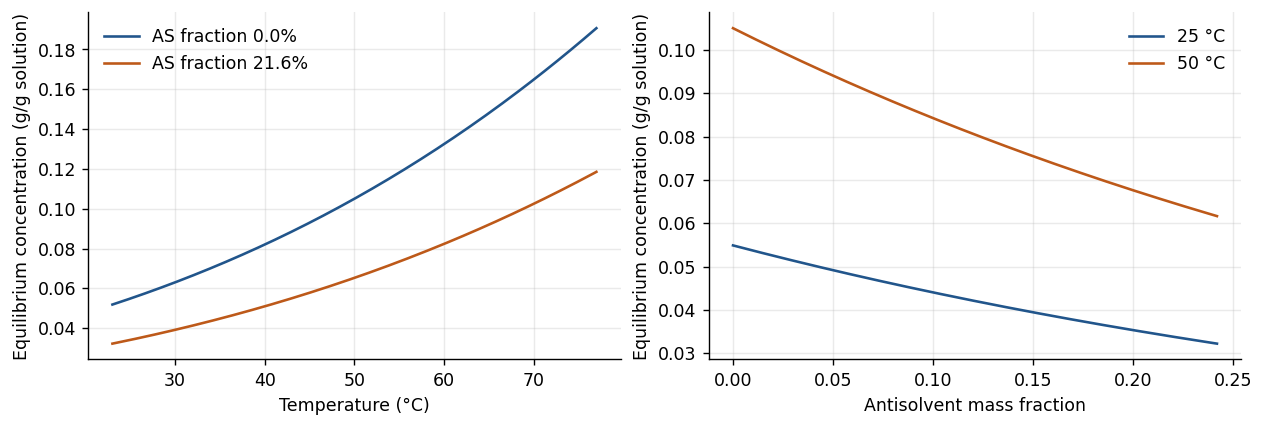

In [4]:
csat_at_50c_no_as = 0.105
temperature_coefficient = -2500.0  # b, kelvin
antisolvent_coefficient = -2.2      # d, per unit mass fraction

solubility = dict.fromkeys("abcdefgh", 0.0)
solubility.update(
    a=np.log(csat_at_50c_no_as) - temperature_coefficient / 323.15,
    b=temperature_coefficient,
    d=antisolvent_coefficient,
)

def equilibrium(temp_c, as_fraction):
    return np.exp(solubility["a"] + solubility["b"] / (np.asarray(temp_c) + 273.15)
                  + solubility["d"] * np.asarray(as_fraction))

knots = np.asarray(time_s, dtype=float)
temperature = np.asarray(temperature_c, dtype=float)
feed = np.asarray(antisolvent_g_s, dtype=float)
if (len(knots) < 2 or knots.shape != temperature.shape or knots.shape != feed.shape
        or not np.isfinite([knots, temperature, feed]).all()
        or knots[0] != 0 or np.any(np.diff(knots) <= 0)
        or np.any(temperature <= -273.15) or np.any(feed < 0)):
    raise ValueError("Use finite profiles of equal length, starting at t=0 with increasing times, "
                     "physical temperatures, and nonnegative feed.")
if (initial_solvent_g <= 0 or initial_antisolvent_g < 0 or not 0 <= initial_concentration < 1
        or not 0 < csat_at_50c_no_as < 1):
    raise ValueError("Check initial liquid masses and concentration mass fractions.")

as_added = np.trapezoid(feed, knots)
initial_as_fraction = initial_antisolvent_g / (initial_solvent_g + initial_antisolvent_g)
final_as_fraction = (initial_antisolvent_g + as_added) / (
    initial_solvent_g + initial_antisolvent_g + as_added)
cold = temperature.min()
hot = temperature[0]
print(f"Antisolvent addition: {as_added:.2f} g | liquid AS fraction: "
      f"{initial_as_fraction:.1%} → {final_as_fraction:.1%}")
print(f"Cooling alone: Csat {equilibrium(hot, initial_as_fraction):.4f} → "
      f"{equilibrium(cold, initial_as_fraction):.4f} g/g solution")
print(f"Antisolvent at {cold:g} °C: Csat {equilibrium(cold, initial_as_fraction):.4f} → "
      f"{equilibrium(cold, final_as_fraction):.4f} g/g solution")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
temp_grid = np.linspace(temperature.min() - 2, temperature.max() + 2, 150)
as_grid = np.linspace(0, max(0.05, final_as_fraction * 1.12), 150)
colors = ("#21558b", "#bd5919")
for fraction, color in zip((initial_as_fraction, final_as_fraction), colors):
    axes[0].plot(temp_grid, equilibrium(temp_grid, fraction),
                 color=color, label=f"AS fraction {fraction:.1%}")
for temp, color in zip((cold, hot), colors):
    axes[1].plot(as_grid, equilibrium(temp, as_grid), color=color, label=f"{temp:g} °C")
axes[0].set(xlabel="Temperature (°C)", ylabel="Equilibrium concentration (g/g solution)")
axes[1].set(xlabel="Antisolvent mass fraction", ylabel="Equilibrium concentration (g/g solution)")
for ax in axes:
    ax.legend(frameon=False)
plt.show()

### Prepare the shared solver inputs

In [5]:
parameter_groups = (primary, secondary, growth, dissolution, agglomeration, breakage)
# Read keys explicitly so dictionary reordering cannot change the IMED parameter vector.
parameter_order = (
    ("kp", "p", "ke", "Ep", "chi_p"),
    ("ks", "s", "j", "js", "Es", "chi_s", "xi_s"),
    ("kg", "g", "alpha_g", "beta_g", "Eg", "chi_g"),
    ("kd", "d", "alpha_d", "beta_d", "Ed", "chi_d"),
    ("ka", "agg", "kernel", "xi_a"),
    ("kbr", "br", "k", "Lcr", "mu_br", "sigma_br", "daughter_law"),
)
parameters = np.array([group[key] for group, order in zip(parameter_groups, parameter_order)
                       for key in order], dtype=float)
log_fields = [0, 3, 5, 9, 12, 16, 18, 22, 24, 28]
if not np.isfinite(parameters).all() or np.any(parameters[log_fields] < 0):
    raise ValueError("Use finite kinetic values and nonnegative rates and activation energies.")
with np.errstate(divide="ignore"):
    parameters[log_fields] = np.log10(parameters[log_fields])

d10, d50, d90 = seed_d10_d50_d90_um
if L_max_um <= 0 or int(bins) != bins or bins < 2 or seed_mass_g < 0:
    raise ValueError("Use a positive mesh limit, at least two cells, and nonnegative seed mass.")
if seed_mass_g and not 0 < d10 < d50 < d90 < 2 * d90 <= L_max_um:
    raise ValueError("Use 0 < D10 < D50 < D90 and L_max >= 2 × D90 for the seeded benchmark.")
if seed_mass_g:
    anchor_sizes = np.array([0.5 * d10, d10, d50, d90, 2 * d90])
    log_cdf = PchipInterpolator(np.log(anchor_sizes), [0, 0.1, 0.5, 0.9, 1],
                               extrapolate=False)
    seed_sizes = np.unique(np.r_[0, np.linspace(anchor_sizes[0], anchor_sizes[-1], 2001),
                                  anchor_sizes, L_max_um])
    density = np.zeros_like(seed_sizes)
    within_seed = (seed_sizes >= anchor_sizes[0]) & (seed_sizes <= anchor_sizes[-1])
    size = seed_sizes[within_seed]
    density[within_seed] = np.maximum(log_cdf.derivative()(np.log(size)) / size, 0)
    density[(seed_sizes == anchor_sizes[0]) | (seed_sizes == anchor_sizes[-1])] = 0
    seed_csd = np.vstack((seed_sizes, density))
else:
    seed_csd = np.empty((2, 0))

experiment = {
    "TemperatureData": np.vstack((knots, temperature)),
    "FlowRateData": np.vstack((knots, feed)),
    "ConcentrationData": np.array([[0], [initial_concentration]]),
    "InitialCSDsData": seed_csd,
}
process = {
    "ShapeFactor": shape_factor, "SolidDensity": solid_density_g_cm3,
    "SolventDensity": solvent_density_g_cm3, "AntiSolventDensity": antisolvent_density_g_cm3,
    "SolvMass": initial_solvent_g, "AntiSolvMass": initial_antisolvent_g,
    "SeedMass": seed_mass_g, "PowerRatio": power_ratio,
}
settings = {
    "Lmin": 0.0, "Lmax": L_max_um, "N": int(bins),
    "RelTol": 5e-7, "AbsTol": 1e-8, "MaxStep": knots[-1] / 170, "MaxIterationTime": 120,
}

### Run PBM and QMOM

Both solvers report at the same times. Crystal mass is solid density times crystal volume. Dissolved API mass uses IMED's solute-to-carrier ratio times the liquid carrier mass. The sum excludes the solvent and antisolvent themselves. Average size is number-weighted, $M_1/M_0$. An empty population has undefined mean size.

In [6]:
count, _, csd, state = simulate(parameters, experiment, process, solubility, settings,
                                return_history=True)
time = count[0]
qmom = solve_ccas_qmom(parameters, experiment, process, solubility, settings, time=time)

bins = settings["N"]
edges = np.linspace(settings["Lmin"], settings["Lmax"], bins + 1)
number_per_bin = state[:bins] * np.diff(edges)[:, None]
pbm_number = number_per_bin.sum(axis=0)
pbm_volume = cell_volumes(edges, shape_factor) @ number_per_bin / 1e12  # cm³
pbm_mean = np.divide(csd[0] @ number_per_bin, pbm_number,
                     out=np.full_like(pbm_number, np.nan), where=pbm_number > 0)

pbm_crystal = solid_density_g_cm3 * pbm_volume
pbm_dissolved = state[bins] * state[bins + 1]
pbm_total = pbm_crystal + pbm_dissolved
qmom_total = qmom.crystal_mass + qmom.dissolved_mass

def max_mass_drift(total):
    return np.max(np.abs(total - total[0]))

print(f"PBM max API mass drift  {max_mass_drift(pbm_total):.3g} g")
print(f"QMOM max API mass drift {max_mass_drift(qmom_total):.3g} g")
print(f"Final crystal mass      PBM {pbm_crystal[-1]:.4g} g | QMOM {qmom.crystal_mass[-1]:.4g} g")

PBM max API mass drift  1.02e-11 g
QMOM max API mass drift 3.74e-12 g
Final crystal mass      PBM 2.522 g | QMOM 2.516 g


### Compare the four trajectories

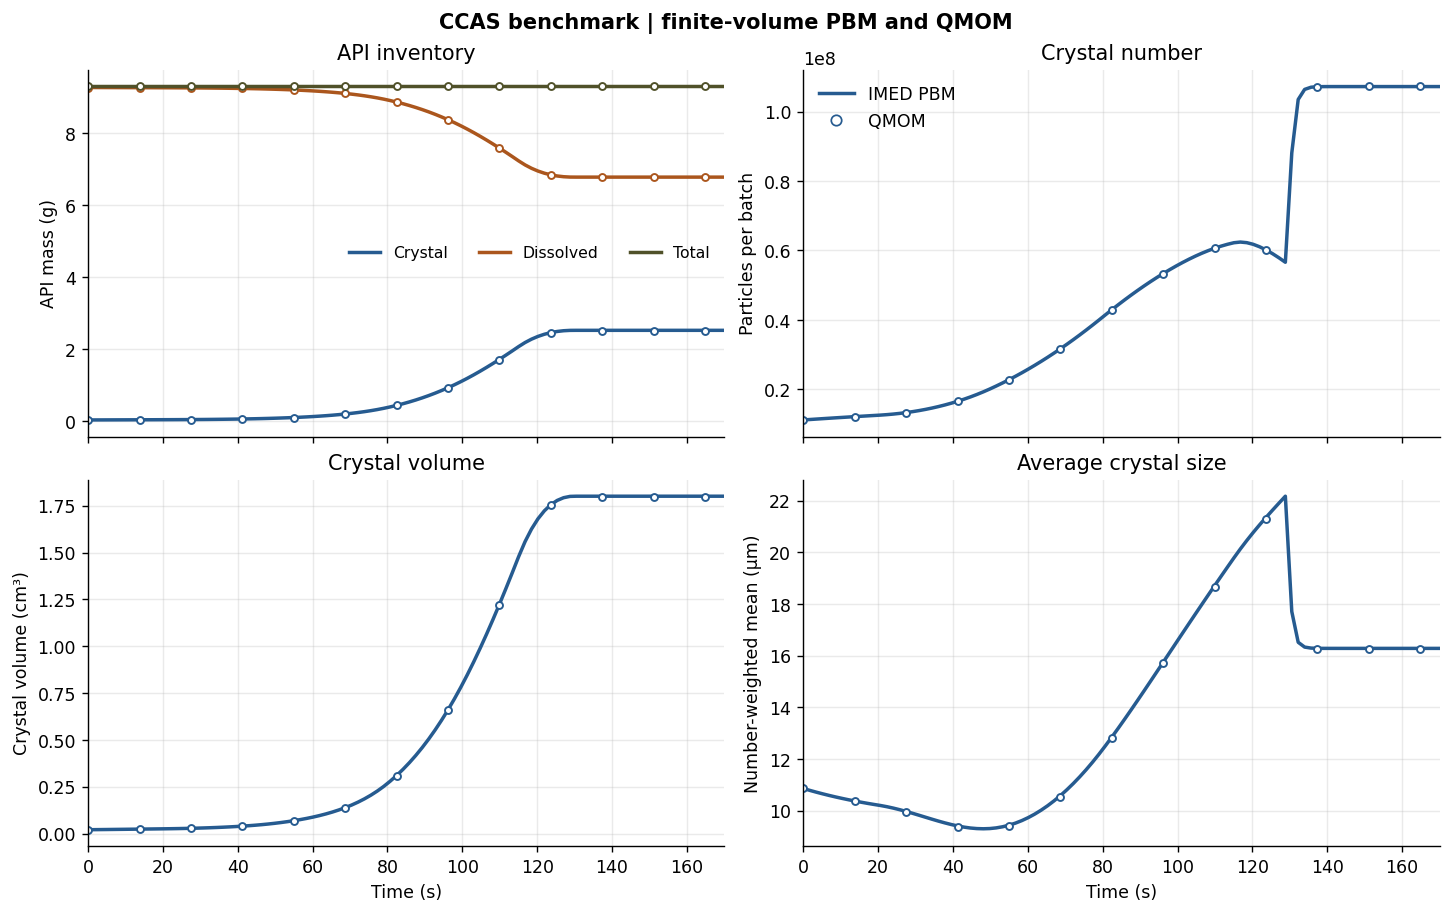

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.2), sharex=True, layout="constrained")
fig.suptitle("CCAS benchmark | finite-volume PBM and QMOM", fontweight="bold")
palette = {"Crystal": "#265b90", "Dissolved": "#ab561d", "Total": "#505129"}

def paired(ax, pbm, reference, color, label=None):
    ax.plot(time, pbm, color=color, lw=2.0, label=label)
    ax.plot(time, reference, color=color, marker="o", markersize=4,
            markevery=8, markerfacecolor="white", markeredgewidth=1.1, lw=0)

for label, pbm, reference in [
    ("Crystal", pbm_crystal, qmom.crystal_mass),
    ("Dissolved", pbm_dissolved, qmom.dissolved_mass),
    ("Total", pbm_total, qmom_total),
]:
    paired(axes[0, 0], pbm, reference, palette[label], label)
axes[0, 0].set(title="API inventory", ylabel="API mass (g)")
axes[0, 0].legend(frameon=False, ncol=3, fontsize=9)

panels = [
    (axes[0, 1], pbm_number, qmom.number, "Crystal number", "Particles per batch"),
    (axes[1, 0], pbm_volume, qmom.volume / 1e12, "Crystal volume", "Crystal volume (cm³)"),
    (axes[1, 1], pbm_mean, qmom.mean_size, "Average crystal size", "Number-weighted mean (µm)"),
]
for ax, pbm, reference, title, unit in panels:
    paired(ax, pbm, reference, palette["Crystal"])
    ax.set(title=title, ylabel=unit)
axes[0, 1].legend(handles=[
    Line2D([], [], color=palette["Crystal"], lw=2, label="IMED PBM"),
    Line2D([], [], color=palette["Crystal"], marker="o", markerfacecolor="white",
           lw=0, label="QMOM"),
], frameon=False)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
axes[0, 0].set_xlim(time[0], time[-1])
plt.show()

### Interpret a run

Compare the lines with the open QMOM markers. The total API curve should stay flat while the crystal and dissolved inventories change. The printed drift exposes small mass changes that may be hard to see on the plot. If crystal sizes approach the mesh limit, increase **L_max** and refine **bins** to check truncation and grid error.

QMOM is a moment closure. Strong size-selective kinetics, a distribution concentrated near the lower size boundary during dissolution, or unusually sharp inputs can limit the comparison. The production IMED finite-volume grid controls PBM resolution. QMOM uses three quadrature nodes and uses the mesh settings for the size-domain and mesh-dependent IMED daughter law.